# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

**Scenario.** A taxi (matatu) association runs 14-seater vehicles on three routes out of Kampala. It wants to forecast
demand, understand fares and decide how many vehicles to deploy. We have 10 days of passenger counts
(Ntinda from the original question, the others illustrative).

Reusable code: `src/taxi.py`.

In [1]:
# --- Imports ----------------------------------------------------------------------

# numpy: arrays and maths
import numpy as np

# pandas: tables
import pandas as pd

# matplotlib: charts
import matplotlib.pyplot as plt

# Our own code from src/taxi.py
from src.taxi import (
    Route,                            # one route: passengers + fare
    market_equilibrium,               # solves the supply/demand system
    MovingAverageForecaster,          # model (a)
    ExponentialSmoothingForecaster,   # model (b)
    LinearTrendForecaster,            # model (c)
    SeasonalNaiveForecaster,          # extension model
    walk_forward_predictions,         # rolling-origin backtest
    walk_forward_mae,                 # its MAE
    tune_alpha,                       # grid search for alpha
    vehicles_needed,                  # fleet planning
    simulate_weekly_passengers,       # extension data
)

SEED = 7
BLUE, ORANGE, AQUA, INK = "#2a78d6", "#eb6834", "#1baf7a", "#3b3a37"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

## Task 1 – The `Route` class

In [2]:
routes = [
    Route("Kampala-Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], fare=2_000),
    Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], fare=5_000),
    Route("Kampala-Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], fare=3_000),
]
for route in routes:
    print(route)

pd.DataFrame([{
    "route": r.name,
    "fare (UGX)": r.fare,
    **{f"passengers {k}": v for k, v in r.describe().items()},
    "avg daily revenue (UGX)": r.daily_revenue().mean(),
    "10-day revenue (UGX)": r.total_revenue(),
} for r in routes]).set_index("route").round(1)

Route('Kampala-Ntinda', 10 days, fare=2,000)
Route('Kampala-Entebbe', 10 days, fare=5,000)
Route('Kampala-Mukono', 10 days, fare=3,000)


,fare (UGX),passengers mean,passengers variance,passengers std_dev,avg daily revenue (UGX),10-day revenue (UGX)
route,,,,,,
Kampala-Ntinda,2000,47.4,54.3,7.4,94800.0,948000.0
Kampala-Entebbe,5000,67.8,45.1,6.7,339000.0,3390000.0
Kampala-Mukono,3000,52.0,26.4,5.1,156000.0,1560000.0


## Task 2 – Supply–demand equilibrium on the Ntinda route

Demand: Q = 120 − 0.02P  Supply: Q = 10 + 0.03P  (P = fare in UGX, Q = passengers per trip-hour)

Moving everything with Q and P to the left gives a 2 × 2 linear system:

$$\begin{bmatrix}1 & 0.02\\ 1 & -0.03\end{bmatrix}\begin{bmatrix}Q\\ P\end{bmatrix} = \begin{bmatrix}120\\ 10\end{bmatrix}$$

In [3]:
eq_price, eq_quantity = market_equilibrium()
print(f"Equilibrium fare:     UGX {eq_price:,.0f}")
print(f"Equilibrium quantity: {eq_quantity:.0f} passengers per trip-hour")

current_fare = 2_000
demand_now = 120 - 0.02 * current_fare
supply_now = 10 + 0.03 * current_fare
print(f"\nAt the current fare of UGX {current_fare:,}: demand = {demand_now:.0f}, supply = {supply_now:.0f}"
      f" -> shortage of {demand_now - supply_now:.0f} passengers per trip-hour")

Equilibrium fare:     UGX 2,200
Equilibrium quantity: 76 passengers per trip-hour

At the current fare of UGX 2,000: demand = 80, supply = 70 -> shortage of 10 passengers per trip-hour


**Interpretation.** The current fare (UGX 2,000) is **UGX 200 below** the equilibrium fare (UGX 2,200). At 2,000,
80 passengers per trip-hour want to travel but operators only offer 70 seats' worth of service, a **shortage of 10**.
In practice that means queues at the stage and full taxis. Operators then have a reason to push the fare up informally
(especially at rush hour or in the rain) until it nears 2,200, where supply and demand balance at 76.
The alternative to raising the fare is adding vehicles (more supply), which is what Task 6 plans.

## Task 3 – Forecaster classes

All models are children of an abstract `Forecaster` parent with `fit(values)` and `predict(horizon)`.

| Model | Rule |
|---|---|
| 3-day moving average | tomorrow = average of the last 3 days (the original method) |
| Exponential smoothing | level = α·today + (1 − α)·previous level; high α reacts fast, low α smooths |
| Linear trend | straight line through all past days, extended one day |

In [4]:
ntinda = routes[0].passengers
for model in [MovingAverageForecaster(3), ExponentialSmoothingForecaster(0.5), LinearTrendForecaster()]:
    print(f"{model.name:30s} forecasts day 11: {model.fit(ntinda).predict(1)[0]:.1f} passengers")

3-day moving average           forecasts day 11: 48.0 passengers
Exp. smoothing (alpha=0.50)    forecasts day 11: 47.2 passengers
Linear trend                   forecasts day 11: 53.7 passengers


## Task 4 – Walk-forward backtesting (days 4–10) and tuning α

**Walk-forward** means: to predict day 4, fit on days 1–3 only. To predict day 5, fit on days 1–4, and so on.
The model never sees the day it is predicting, just as in real life.
α is tuned by **grid search**: try α = 0.05, 0.10, …, 1.00 and keep the one with the lowest MAE.

In [5]:
best_alpha = {}          # route name -> tuned alpha
mae_rows = []
for route in routes:
    alpha, _ = tune_alpha(route.passengers, first_day=4)
    best_alpha[route.name] = alpha
    models = [MovingAverageForecaster(3), ExponentialSmoothingForecaster(alpha), LinearTrendForecaster()]
    row = {"route": route.name, "tuned alpha": alpha}
    for model in models:
        # we store MAE by model TYPE so the columns line up across routes
        kind = model.name.split(" (")[0]
        row[kind] = walk_forward_mae(model, route.passengers, first_day=4)
    mae_rows.append(row)

mae_table = pd.DataFrame(mae_rows).set_index("route")
print("MAE in passengers per day (lower is better):")
mae_table.round(2)

MAE in passengers per day (lower is better):


,tuned alpha,3-day moving average,Exp. smoothing,Linear trend
route,,,,
Kampala-Ntinda,1.0,7.52,5.86,7.87
Kampala-Entebbe,1.0,7.19,4.43,7.71
Kampala-Mukono,1.0,5.33,3.71,6.39


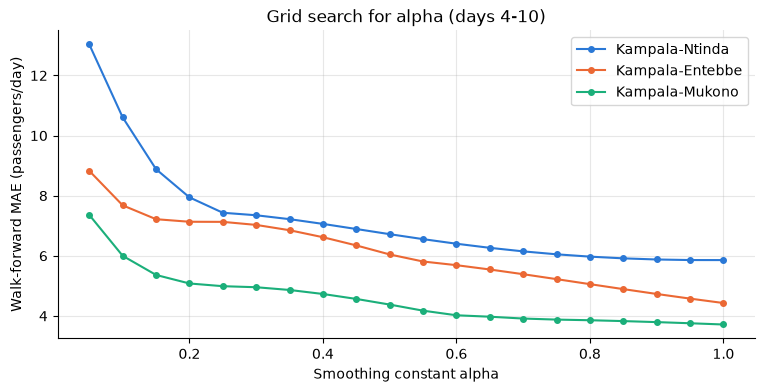

In [6]:
# How MAE changes with alpha on each route (the grid search, drawn)
alphas = np.round(np.arange(0.05, 1.0001, 0.05), 2)
fig, ax = plt.subplots(figsize=(9, 4))
for colour, route in zip([BLUE, ORANGE, AQUA], routes):
    errors = [walk_forward_mae(ExponentialSmoothingForecaster(a), route.passengers) for a in alphas]
    ax.plot(alphas, errors, "o-", color=colour, ms=4, label=route.name)
ax.set_xlabel("Smoothing constant alpha")
ax.set_ylabel("Walk-forward MAE (passengers/day)")
ax.set_title("Grid search for alpha (days 4-10)")
ax.legend()
plt.show()

## Task 5 – Forecast day 11 with the best model

In [7]:
def make_model(kind: str, alpha: float):
    # Turn a column name from the MAE table back into a fresh model object.
    if kind == "3-day moving average":
        return MovingAverageForecaster(3)
    if kind == "Exp. smoothing":
        return ExponentialSmoothingForecaster(alpha)
    return LinearTrendForecaster()

model_columns = ["3-day moving average", "Exp. smoothing", "Linear trend"]
day11 = {}               # route name -> forecast passengers on day 11
chosen = {}              # route name -> model object used
forecast_rows = []
for route in routes:
    best_kind = mae_table.loc[route.name, model_columns].astype(float).idxmin()   # column with lowest MAE
    model = make_model(best_kind, best_alpha[route.name])
    chosen[route.name] = model
    passengers_11 = model.fit(route.passengers).predict(1)[0]        # fit on all 10 days
    day11[route.name] = passengers_11
    forecast_rows.append({"route": route.name, "best model": model.name,
                          "day 11 passengers": round(passengers_11, 1),
                          "day 11 revenue (UGX)": round(passengers_11 * route.fare)})
pd.DataFrame(forecast_rows).set_index("route")

,best model,day 11 passengers,day 11 revenue (UGX)
route,,,
Kampala-Ntinda,Exp. smoothing (alpha=1.00),45.0,90000
Kampala-Entebbe,Exp. smoothing (alpha=1.00),64.0,320000
Kampala-Mukono,Exp. smoothing (alpha=1.00),50.0,150000


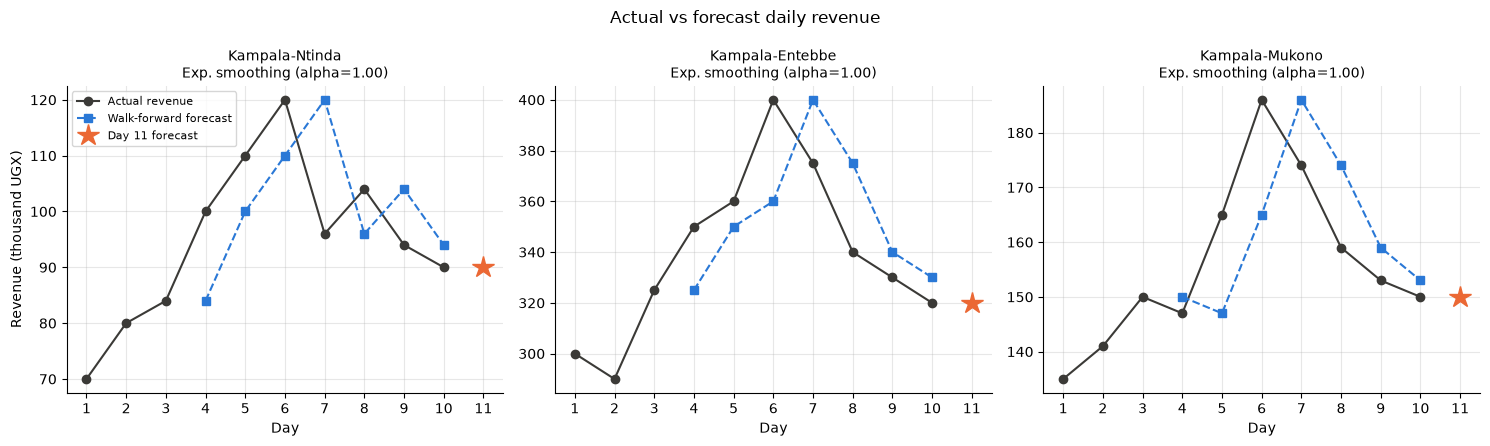

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for ax, route in zip(axes, routes):
    model = chosen[route.name]
    actual, predicted = walk_forward_predictions(model, route.passengers, first_day=4)
    ax.plot(range(1, 11), route.daily_revenue() / 1000, "o-", color=INK, label="Actual revenue")
    ax.plot(range(4, 11), predicted * route.fare / 1000, "s--", color=BLUE, label="Walk-forward forecast")
    ax.plot([11], [day11[route.name] * route.fare / 1000], "*", color=ORANGE, ms=16, label="Day 11 forecast")
    ax.set_title(f"{route.name}\n{model.name}", fontsize=10)
    ax.set_xlabel("Day")
    ax.set_xticks(range(1, 12))
axes[0].set_ylabel("Revenue (thousand UGX)")
axes[0].legend(fontsize=8)
fig.suptitle("Actual vs forecast daily revenue")
fig.tight_layout()
plt.show()

## Task 6 – Fleet planning for day 11

One vehicle: 8 one-way trips × 14 seats = **112 passengers per day**. Add a **15% buffer**, then **round up**
(half a taxi is impossible, and rounding down would leave passengers stranded).

In [9]:
fleet_rows = []
for route in routes:
    expected = day11[route.name]
    fleet_rows.append({
        "route": route.name,
        "forecast passengers": round(expected, 1),
        "with 15% buffer": round(expected * 1.15, 1),
        "capacity per vehicle": 8 * 14,
        "vehicles needed": vehicles_needed(expected),
        "seat utilisation": f"{expected / (vehicles_needed(expected) * 112):.0%}",
    })
pd.DataFrame(fleet_rows).set_index("route")

,forecast passengers,with 15% buffer,capacity per vehicle,vehicles needed,seat utilisation
route,,,,,
Kampala-Ntinda,45.0,51.7,112,1,40%
Kampala-Entebbe,64.0,73.6,112,1,57%
Kampala-Mukono,50.0,57.5,112,1,45%


One vehicle per route is enough on day 11: even Entebbe's 64 passengers (about 74 with the buffer) fit in 112 seats.
Note the tension with Task 2: the equilibrium model describes **80 passengers per trip-hour** on Ntinda, far above
the ~45–60 *per day* in the counts. The two data sources don't describe the same thing (the counts are probably one
stage or one vehicle's tally), so the fleet answer is only as good as the passenger data behind it.

## Extension – Weekly seasonality: seasonal-naive vs moving average

We simulate **60 days** (day 1 = Monday) where Fridays are ~40% busier and Sundays ~40% quieter, plus noise (seeded).
The **seasonal-naive** model predicts "same weekday last week".

3-day moving average      walk-forward MAE (days 8-60): 11.42 passengers
Seasonal naive (7-day)    walk-forward MAE (days 8-60): 3.25 passengers


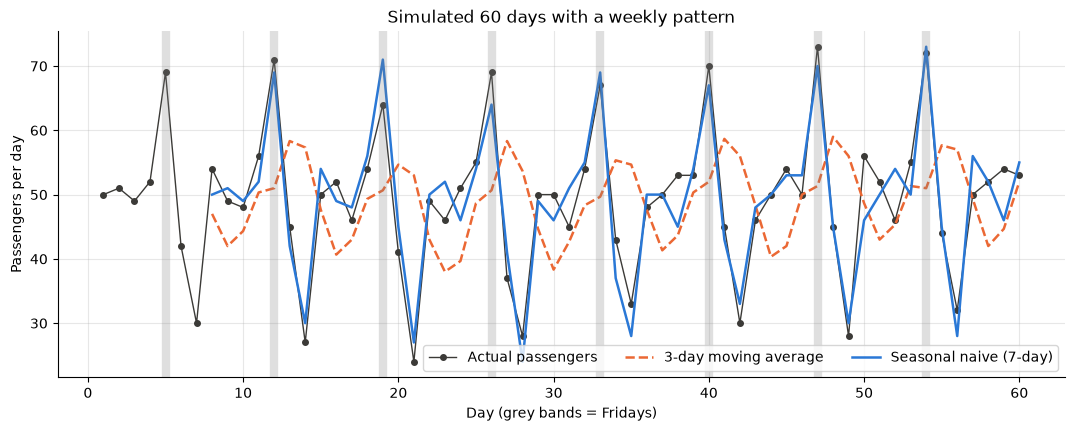

In [10]:
weekly = simulate_weekly_passengers(days=60, base=50, seed=SEED)
FIRST = 8      # both models need a full week of history before the first prediction

results = {}
for model in [MovingAverageForecaster(3), SeasonalNaiveForecaster(7)]:
    actual, predicted = walk_forward_predictions(model, weekly, first_day=FIRST)
    results[model.name] = predicted
    print(f"{model.name:25s} walk-forward MAE (days {FIRST}-60): {walk_forward_mae(model, weekly, FIRST):.2f} passengers")

fig, ax = plt.subplots(figsize=(13, 4.5))
days = np.arange(1, 61)
ax.plot(days, weekly, "o-", color=INK, ms=4, lw=1, label="Actual passengers")
ax.plot(days[FIRST - 1:], results["3-day moving average"], "--", color=ORANGE, lw=1.8, label="3-day moving average")
ax.plot(days[FIRST - 1:], results["Seasonal naive (7-day)"], "-", color=BLUE, lw=1.8, label="Seasonal naive (7-day)")
for friday in range(5, 61, 7):
    ax.axvline(friday, color="grey", alpha=0.25, lw=6)
ax.set_xlabel("Day (grey bands = Fridays)")
ax.set_ylabel("Passengers per day")
ax.set_title("Simulated 60 days with a weekly pattern")
ax.legend(ncol=3)
plt.show()

The moving average always **lags**: it averages Wednesday–Thursday to predict Friday (too low), then carries the
Friday rush into Saturday–Sunday (too high). The seasonal-naive model knows "Fridays are busy" because it copies last
Friday, so its errors are only the random noise. Whenever demand follows the calendar, a forecaster must model the
calendar. A smoothing method, however well tuned, can't see it.

## Findings & Limitations

**Findings.** The Entebbe route is the association's revenue engine: it carries about 41% of passengers but earns
57% of revenue, because its fare is 2.5 times Ntinda's. On Ntinda, the fare (UGX 2,000) is UGX 200 below the
equilibrium of UGX 2,200. That creates a shortage of about 10 passengers per trip-hour, which explains the pressure
for informal fare rises at busy times. The association could either accept a modest increase or add capacity.

In forecasting, the grid search chose **α = 1.0 on every route**. That means the best forecast for tomorrow was simply
*today's* count. The ten days show demand rising to a peak on day 6 and then easing off, so the most recent day is
more informative than an average of three. Averaging makes the forecast lag behind every turn. Exponential smoothing
beat the 3-day moving average by 22–38% in MAE, and the linear trend was worst on every route, because a straight line
through a rise-and-fall shape points in the wrong direction. Day-11 forecasts are 45, 64 and 50 passengers, and each
route needs just one vehicle, running at 40–57% of seat capacity.

The extension shows what the short data hides. With a weekly pattern, seasonal-naive (MAE 3.3) beats the moving
average (MAE 11.4), so the association should collect several weeks of data labelled by weekday.

**Limitations.** Ten days is far too short. Walk-forward testing rests on only 7 predictions per route, so the ranking
of models is fragile, and α = 1 lies on the edge of the grid. The demand and supply equations were given, not
estimated. Their scale (passengers per trip-hour) doesn't match the daily counts, so the equilibrium and fleet results
describe different things. The fleet rule ignores rush-hour peaks, when most trips are needed at the same time.